In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import joblib
import gc
import time

import pyarrow.parquet as pq

from pathlib import Path

from sklearn.ensemble import IsolationForest
from sklearn.neural_network import MLPRegressor

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    FunctionTransformer
)

from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from threadpoolctl import threadpool_limits

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
    roc_curve,
    confusion_matrix
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

RANDOM_STATE = 42
N_JOBS = 2

DATA_PATH = Path("../data/processed")
MODEL_PATH = Path("../models")
RESULTS_PATH = Path("../reports/results")

MODEL_PATH.mkdir(parents=True, exist_ok=True)
RESULTS_PATH.mkdir(parents=True, exist_ok=True)

FIGURES_PATH = Path("../reports/figures")
FIGURES_PATH.mkdir(parents=True, exist_ok=True)


def save_plot(filename):
    plt.tight_layout()
    plt.savefig(
        FIGURES_PATH / filename,
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()


In [2]:
with open(DATA_PATH / "feature_metadata.json", "r") as f:
    metadata = json.load(f)

feature_columns = metadata["feature_columns"]
feature_groups = metadata["feature_groups"]
target_column = metadata["target_column"]

previous_results = pd.read_csv(
    RESULTS_PATH / "all_model_results.csv"
)

previous_results.head()

,model,threshold,accuracy,precision,recall,f1,average_precision,roc_auc,fraud_value_captured,true_positives,false_positives,true_negatives,false_negatives,algorithm,training_time_seconds,best_iteration,training_rows,negative_sample_rate,weighting
0,XGBoost - Shallow - 10% Sample,0.5,0.994200,0.979079,0.150773,0.261307,0.608008,0.968510,0.367950,234,5,226546,1318,xgboost,13.313963,75.0,604778.0,0.10,population
1,XGBoost - Shallow,0.5,0.994546,0.975309,0.203608,0.336887,0.603106,0.969962,0.455257,316,8,226543,1236,xgboost,21.507963,164.0,305142.0,0.05,population
2,XGBoost - Regularized,0.5,0.994029,0.994792,0.123067,0.219037,0.593509,0.967893,0.289049,191,1,226550,1361,xgboost,13.293794,102.0,305142.0,0.05,population
3,LightGBM - Population Weighted,0.5,0.993924,1.000000,0.106959,0.193248,0.590204,0.971202,0.325844,166,0,226551,1386,lightgbm,8.315666,21.0,305142.0,0.05,population
4,XGBoost - Deep,0.5,0.994117,0.990654,0.136598,0.240091,0.589572,0.967772,0.340465,212,2,226549,1340,xgboost,10.756691,57.0,305142.0,0.05,population


In [3]:
xgb_model = joblib.load(
    MODEL_PATH / "best_xgboost.joblib"
)

In [4]:
NORMAL_SAMPLE_RATE = 0.02
BATCH_SIZE = 100_000

def load_normal_training_sample(
    sample_rate=0.02,
    batch_size=100_000
):

    rng = np.random.default_rng(RANDOM_STATE)

    train_file = pq.ParquetFile(
        DATA_PATH / "train.parquet"
    )

    sampled_batches = []

    for batch in train_file.iter_batches(
        batch_size=batch_size,
        columns=feature_columns + [target_column]
    ):

        chunk = batch.to_pandas()

        normal_mask = chunk[target_column] == 0

        random_mask = (
            rng.random(len(chunk)) < sample_rate
        )

        keep_mask = normal_mask & random_mask

        sampled_batches.append(
            chunk.loc[keep_mask].copy()
        )

        del chunk

    sampled_data = pd.concat(
        sampled_batches,
        ignore_index=True
    )

    del sampled_batches
    gc.collect()

    return sampled_data

In [5]:
normal_df = load_normal_training_sample(
    sample_rate=NORMAL_SAMPLE_RATE,
    batch_size=BATCH_SIZE
)

print("Normal training shape:", normal_df.shape)

assert normal_df[target_column].eq(0).all()

normal_df[target_column].value_counts()

Normal training shape: (119867, 13)


isFraud
0    119867
Name: count, dtype: int64

In [6]:
normal_train_df, normal_reference_df = train_test_split(
    normal_df,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("Normal training:", normal_train_df.shape)
print("Normal reference:", normal_reference_df.shape)

del normal_df
gc.collect()

Normal training: (95893, 13)
Normal reference: (23974, 13)


0

In [7]:
val_df = pd.read_parquet(
    DATA_PATH / "validation.parquet",
    columns=feature_columns + [target_column]
)

X_normal = normal_train_df[feature_columns]

X_reference = normal_reference_df[feature_columns]

X_val = val_df[feature_columns]
y_val = val_df[target_column]

print("Training:", X_normal.shape)
print("Reference:", X_reference.shape)
print("Validation:", X_val.shape)

Training: (95893, 12)
Reference: (23974, 12)
Validation: (228103, 12)


In [8]:
anomaly_features = [
    col for col in feature_columns
    if col != "amount"
]

categorical_features = ["type"]

binary_features = [
    "recipient_is_merchant",
    "recipient_is_new"
]

skewed_features = [
    "recipient_prior_count",
    "recipient_prior_total",
    "recipient_prior_mean",
    "recipient_hours_since_last",
    "amount_to_recipient_mean"
]

numerical_features = [
    col for col in anomaly_features
    if col not in (
        categorical_features
        + binary_features
        + skewed_features
    )
]

In [9]:
skewed_pipeline = Pipeline([
    (
        "log_transform",
        FunctionTransformer(
            np.log1p,
            feature_names_out="one-to-one"
        )
    ),
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    )
])

numerical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    )
])

In [10]:
preprocessor = ColumnTransformer([
    (
        "skewed",
        skewed_pipeline,
        skewed_features
    ),
    (
        "numerical",
        numerical_pipeline,
        numerical_features
    ),
    (
        "binary",
        "passthrough",
        binary_features
    ),
    (
        "categorical",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False,
            dtype=np.float32
        ),
        categorical_features
    )
])

In [11]:
X_normal_processed = (
    preprocessor.fit_transform(X_normal)
    .astype(np.float32)
)

X_reference_processed = (
    preprocessor.transform(X_reference)
    .astype(np.float32)
)

X_val_processed = (
    preprocessor.transform(X_val)
    .astype(np.float32)
)

print("Processed training:", X_normal_processed.shape)
print("Processed reference:", X_reference_processed.shape)
print("Processed validation:", X_val_processed.shape)

Processed training: (95893, 15)
Processed reference: (23974, 15)
Processed validation: (228103, 15)


In [12]:
for dataset in [
    X_normal_processed,
    X_reference_processed,
    X_val_processed
]:

    assert np.isfinite(dataset).all()

print("All preprocessing validation checks passed.")

All preprocessing validation checks passed.


In [13]:
isolation_params = {
    "n_estimators": 150,
    "max_samples": 1024,
    "contamination": "auto",
    "random_state": RANDOM_STATE,
    "n_jobs": N_JOBS
}

isolation_model = IsolationForest(
    **isolation_params
)

start_time = time.perf_counter()

isolation_model.fit(X_normal_processed)

isolation_training_time = (
    time.perf_counter() - start_time
)

print(
    f"Training time: {isolation_training_time:.2f} seconds"
)

Training time: 0.47 seconds


In [14]:
isolation_scores = -isolation_model.score_samples(
    X_val_processed
)

isolation_reference_scores = (
    -isolation_model.score_samples(
        X_reference_processed
    )
)

pd.Series(isolation_scores).describe()

count    228103.000000
mean          0.492783
std           0.046880
min           0.407719
25%           0.457280
50%           0.485909
75%           0.519201
max           0.723674
dtype: float64

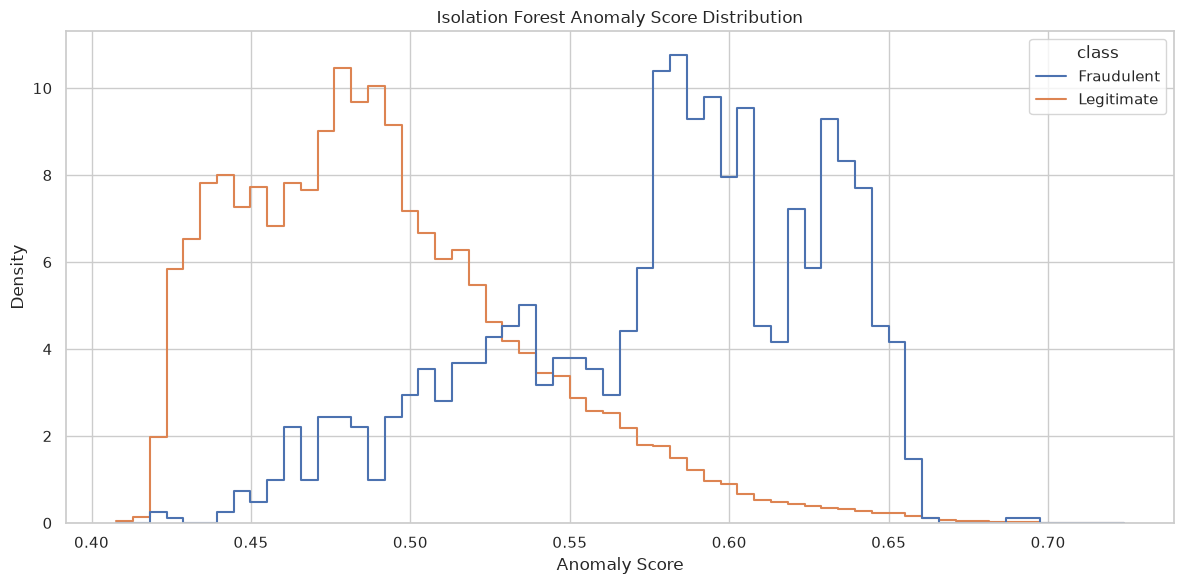

In [15]:
isolation_plot_df = pd.DataFrame({
    "anomaly_score": isolation_scores,
    "isFraud": y_val.to_numpy()
})

isolation_plot_df["class"] = (
    isolation_plot_df["isFraud"]
    .map({
        0: "Legitimate",
        1: "Fraudulent"
    })
)

plt.figure(figsize=(12, 6))

sns.histplot(
    data=isolation_plot_df,
    x="anomaly_score",
    hue="class",
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
    bins=60
)

plt.title("Isolation Forest Anomaly Score Distribution")
plt.xlabel("Anomaly Score")
plt.ylabel("Density")
save_plot("anomaly_isolation_score_distribution.png")

In [16]:
isolation_plot_df.groupby(
    "class"
)["anomaly_score"].describe()

,count,mean,std,min,25%,50%,75%,max
class,,,,,,,,
Fraudulent,1552.0,0.577705,0.051342,0.420275,0.540543,0.586380,0.619540,0.693499
Legitimate,226551.0,0.492201,0.046314,0.407719,0.457017,0.485603,0.518522,0.723674


In [17]:
autoencoder_params = {
    "hidden_layer_sizes": (32, 8, 32),
    "activation": "relu",
    "solver": "adam",
    "learning_rate_init": 0.001,
    "batch_size": 512,
    "max_iter": 60,
    "alpha": 0.0001,
    "early_stopping": True,
    "validation_fraction": 0.10,
    "n_iter_no_change": 8,
    "random_state": RANDOM_STATE
}

autoencoder = MLPRegressor(
    **autoencoder_params
)

In [18]:
start_time = time.perf_counter()

with threadpool_limits(limits=N_JOBS):

    autoencoder.fit(
        X_normal_processed,
        X_normal_processed
    )

autoencoder_training_time = (
    time.perf_counter() - start_time
)

print(
    f"Training time: {autoencoder_training_time:.2f} seconds"
)

print("Training iterations:", autoencoder.n_iter_)
print("Final training loss:", autoencoder.loss_)

Training time: 10.38 seconds
Training iterations: 60
Final training loss: 0.0005435170090220405


/mnt/c/Users/Nathan Huang/fraud-detection-platform/.venv/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (60) reached and the optimization hasn't converged yet.
  warnings.warn(


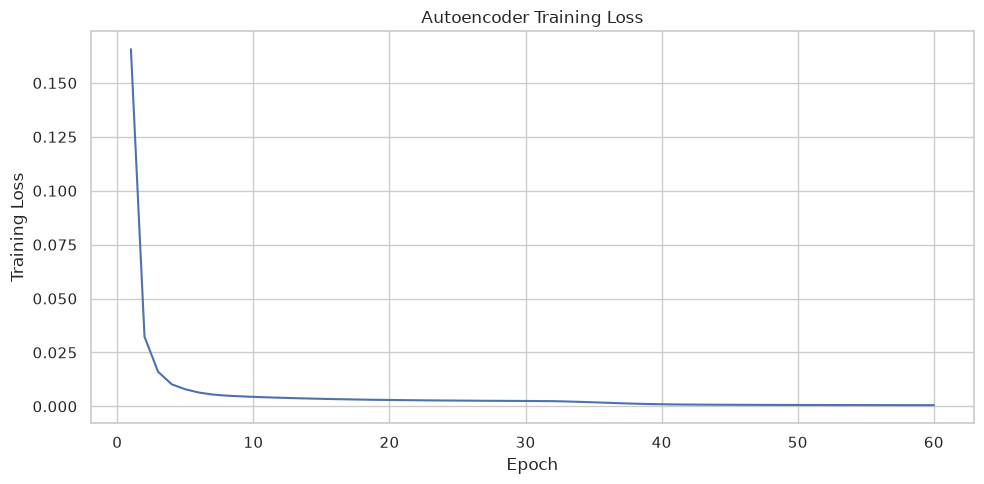

In [19]:
plt.figure(figsize=(10, 5))

plt.plot(
    np.arange(1, autoencoder.n_iter_ + 1),
    autoencoder.loss_curve_
)

plt.title("Autoencoder Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
save_plot("anomaly_autoencoder_training_loss.png")

In [20]:
def calculate_reconstruction_errors(
    model,
    X,
    batch_size=25_000
):

    errors = np.empty(len(X), dtype=np.float64)

    with threadpool_limits(limits=N_JOBS):

        for start in range(0, len(X), batch_size):

            end = min(start + batch_size, len(X))

            batch = X[start:end]

            reconstructed = model.predict(batch)

            errors[start:end] = np.mean(
                (batch - reconstructed) ** 2,
                axis=1
            )

    return errors

In [21]:
autoencoder_scores = calculate_reconstruction_errors(
    autoencoder,
    X_val_processed
)

autoencoder_reference_scores = (
    calculate_reconstruction_errors(
        autoencoder,
        X_reference_processed
    )
)

pd.Series(autoencoder_scores).describe()

count    228103.000000
mean          0.001440
std           0.009313
min           0.000009
25%           0.000036
50%           0.000117
75%           0.000256
max           0.355999
dtype: float64

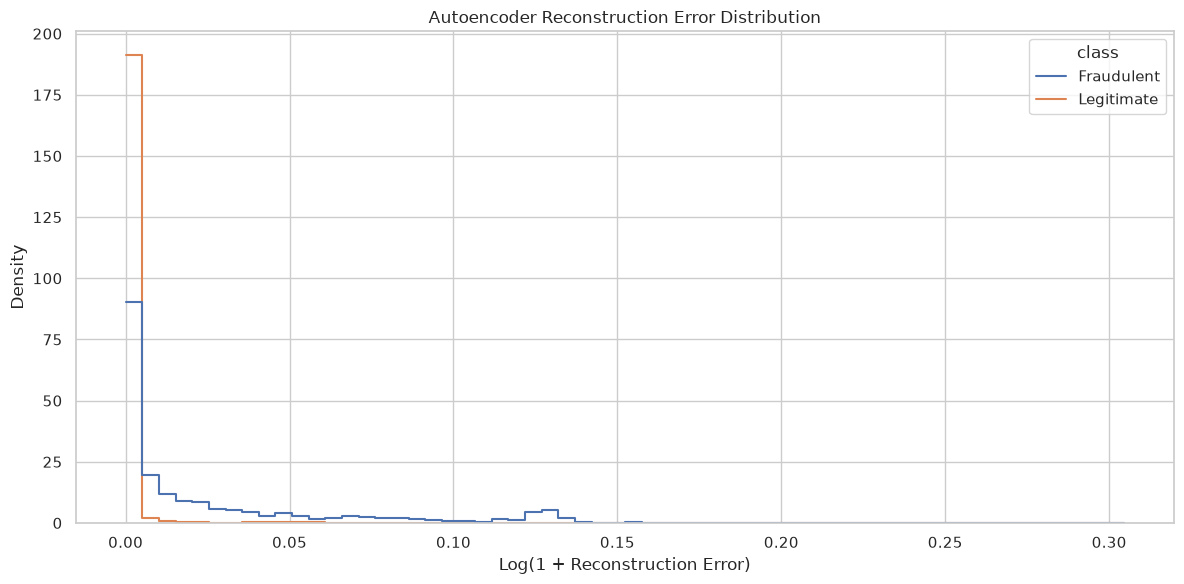

In [22]:
autoencoder_plot_df = pd.DataFrame({
    "reconstruction_error": autoencoder_scores,
    "isFraud": y_val.to_numpy()
})

autoencoder_plot_df["class"] = (
    autoencoder_plot_df["isFraud"]
    .map({
        0: "Legitimate",
        1: "Fraudulent"
    })
)

autoencoder_plot_df["log_error"] = np.log1p(
    autoencoder_plot_df["reconstruction_error"]
)

plt.figure(figsize=(12, 6))

sns.histplot(
    data=autoencoder_plot_df,
    x="log_error",
    hue="class",
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
    bins=60
)

plt.title("Autoencoder Reconstruction Error Distribution")
plt.xlabel("Log(1 + Reconstruction Error)")
plt.ylabel("Density")
save_plot("anomaly_reconstruction_error_distribution.png")

In [23]:
autoencoder_plot_df.groupby(
    "class"
)["reconstruction_error"].describe()

,count,mean,std,min,25%,50%,75%,max
class,,,,,,,,
Fraudulent,1552.0,0.026736,0.040190,0.000037,0.000475,0.007109,0.034156,0.168540
Legitimate,226551.0,0.001266,0.008477,0.000009,0.000035,0.000116,0.000252,0.355999


In [24]:
xgb_scores = xgb_model.predict_proba(
    X_val
)[:, 1]

xgb_reference_scores = xgb_model.predict_proba(
    X_reference
)[:, 1]

In [25]:
def evaluate_anomaly_model(
    model_name,
    y_true,
    y_score,
    amounts,
    alert_rate=0.01
):

    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score)
    amounts = np.asarray(amounts, dtype=np.float64)

    assert len(y_true) == len(y_score)
    assert np.isfinite(y_score).all()

    alert_count = max(
        1,
        int(len(y_true) * alert_rate)
    )

    ranked_indices = np.argsort(
        -y_score,
        kind="stable"
    )

    selected_indices = ranked_indices[:alert_count]

    y_pred = np.zeros(len(y_true), dtype=int)
    y_pred[selected_indices] = 1

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    total_fraud_amount = amounts[y_true == 1].sum()

    detected_fraud_amount = amounts[
        (y_true == 1) & (y_pred == 1)
    ].sum()

    return {
        "model": model_name,
        "average_precision": average_precision_score(
            y_true, y_score
        ),
        "roc_auc": roc_auc_score(
            y_true, y_score
        ),
        "alert_rate": alert_rate,
        "alert_count": alert_count,
        "precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "f1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "fraud_value_captured": (
            detected_fraud_amount / total_fraud_amount
            if total_fraud_amount > 0 else 0
        ),
        "true_positives": tp,
        "false_positives": fp,
        "true_negatives": tn,
        "false_negatives": fn
    }

In [26]:
predictions = {
    "XGBoost": xgb_scores,
    "Isolation Forest": isolation_scores,
    "Autoencoder": autoencoder_scores
}

results = []

for model_name, scores in predictions.items():

    metrics = evaluate_anomaly_model(
        model_name,
        y_val,
        scores,
        val_df["amount"]
    )

    results.append(metrics)

standalone_results = (
    pd.DataFrame(results)
    .sort_values("average_precision", ascending=False)
    .reset_index(drop=True)
)

standalone_results.round(6)

,model,average_precision,roc_auc,alert_rate,alert_count,precision,recall,f1,fraud_value_captured,true_positives,false_positives,true_negatives,false_negatives
0,XGBoost,0.608008,0.968510,0.01,2281,0.418238,0.614691,0.497782,0.918656,954,1327,225224,598
1,Autoencoder,0.108950,0.889739,0.01,2281,0.137221,0.201675,0.163319,0.433310,313,1968,224583,1239
2,Isolation Forest,0.065316,0.880083,0.01,2281,0.108286,0.159149,0.128881,0.192137,247,2034,224517,1305


In [27]:
def get_flagged_indices(scores, alert_rate=0.01):

    alert_count = max(
        1,
        int(len(scores) * alert_rate)
    )

    return set(
        np.argsort(
            -np.asarray(scores),
            kind="stable"
        )[:alert_count]
    )

In [28]:
fraud_indices = set(
    np.flatnonzero(y_val.to_numpy() == 1)
)

xgb_detected = (
    get_flagged_indices(xgb_scores)
    & fraud_indices
)

isolation_detected = (
    get_flagged_indices(isolation_scores)
    & fraud_indices
)

autoencoder_detected = (
    get_flagged_indices(autoencoder_scores)
    & fraud_indices
)

In [29]:
overlap_results = pd.DataFrame([
    {
        "model": "Isolation Forest",
        "fraud_detected": len(isolation_detected),
        "also_detected_by_xgboost": len(
            isolation_detected & xgb_detected
        ),
        "missed_by_xgboost": len(
            isolation_detected - xgb_detected
        )
    },
    {
        "model": "Autoencoder",
        "fraud_detected": len(autoencoder_detected),
        "also_detected_by_xgboost": len(
            autoencoder_detected & xgb_detected
        ),
        "missed_by_xgboost": len(
            autoencoder_detected - xgb_detected
        )
    }
])

overlap_results

,model,fraud_detected,also_detected_by_xgboost,missed_by_xgboost
0,Isolation Forest,247,247,0
1,Autoencoder,313,213,100


In [30]:
def percentile_transform(scores, reference_scores):

    sorted_reference = np.sort(
        np.asarray(reference_scores)
    )

    percentiles = np.searchsorted(
        sorted_reference,
        np.asarray(scores),
        side="right"
    ) / len(sorted_reference)

    return percentiles

In [31]:
xgb_normalized = percentile_transform(
    xgb_scores,
    xgb_reference_scores
)

isolation_normalized = percentile_transform(
    isolation_scores,
    isolation_reference_scores
)

autoencoder_normalized = percentile_transform(
    autoencoder_scores,
    autoencoder_reference_scores
)

In [32]:
normalization_results = pd.DataFrame([
    evaluate_anomaly_model(
        "Original XGBoost",
        y_val,
        xgb_scores,
        val_df["amount"]
    ),
    evaluate_anomaly_model(
        "Percentile-Normalized XGBoost",
        y_val,
        xgb_normalized,
        val_df["amount"]
    )
])

normalization_results.round(6)

,model,average_precision,roc_auc,alert_rate,alert_count,precision,recall,f1,fraud_value_captured,true_positives,false_positives,true_negatives,false_negatives
0,Original XGBoost,0.608008,0.968510,0.01,2281,0.418238,0.614691,0.497782,0.918656,954,1327,225224,598
1,Percentile-Normalized XGBoost,0.592769,0.968498,0.01,2281,0.417799,0.614046,0.497261,0.918646,953,1328,225223,599


In [33]:
anomaly_weights = [0.10, 0.25, 0.50]

anomaly_predictions = {
    "Isolation Forest": isolation_normalized,
    "Autoencoder": autoencoder_normalized,
    "Combined Anomaly": (
        isolation_normalized
        + autoencoder_normalized
    ) / 2
}

hybrid_configs = {}

for anomaly_name, anomaly_scores in anomaly_predictions.items():

    for weight in anomaly_weights:

        hybrid_scores = (
            (1 - weight) * xgb_normalized
            + weight * anomaly_scores
        )

        model_name = (
            f"XGBoost + {anomaly_name} "
            f"({weight:.0%})"
        )

        predictions[model_name] = hybrid_scores

        hybrid_configs[model_name] = {
            "anomaly_model": anomaly_name,
            "anomaly_weight": weight
        }

        metrics = evaluate_anomaly_model(
            model_name,
            y_val,
            hybrid_scores,
            val_df["amount"]
        )

        results.append(metrics)

In [34]:
results_df = (
    pd.DataFrame(results)
    .sort_values("average_precision", ascending=False)
    .reset_index(drop=True)
)

comparison_columns = [
    "model",
    "average_precision",
    "roc_auc",
    "precision",
    "recall",
    "f1",
    "fraud_value_captured",
    "false_positives"
]

results_df[comparison_columns].round(6)

,model,average_precision,roc_auc,precision,recall,f1,fraud_value_captured,false_positives
0,XGBoost,0.608008,0.968510,0.418238,0.614691,0.497782,0.918656,1327
1,XGBoost + Autoencoder (10%),0.492460,0.967269,0.398509,0.585696,0.474302,0.871700,1372
2,XGBoost + Isolation Forest (10%),0.492212,0.966835,0.392372,0.576675,0.466997,0.833349,1386
3,XGBoost + Combined Anomaly (10%),0.485347,0.967313,0.406401,0.597294,0.483694,0.886246,1354
4,XGBoost + Isolation Forest (25%),0.441392,0.962846,0.359491,0.528351,0.427863,0.763746,1461
5,XGBoost + Combined Anomaly (25%),0.434243,0.964548,0.374397,0.550258,0.445604,0.811022,1427
6,XGBoost + Autoencoder (25%),0.429796,0.964035,0.387988,0.570232,0.461779,0.838177,1396
7,XGBoost + Combined Anomaly (50%),0.389370,0.954605,0.346339,0.509021,0.412210,0.738336,1491
8,XGBoost + Isolation Forest (50%),0.382273,0.950119,0.307760,0.452320,0.366293,0.664991,1579
9,XGBoost + Autoencoder (50%),0.346822,0.950474,0.369136,0.542526,0.439343,0.811746,1439


In [35]:
xgb_ap = average_precision_score(
    y_val,
    xgb_scores
)

results_df["ap_improvement"] = (
    results_df["average_precision"] - xgb_ap
)

results_df["relative_ap_improvement_pct"] = (
    results_df["ap_improvement"] / xgb_ap * 100
)

results_df[[
    "model",
    "average_precision",
    "ap_improvement",
    "relative_ap_improvement_pct"
]].round(6)

,model,average_precision,ap_improvement,relative_ap_improvement_pct
0,XGBoost,0.608008,0.000000,0.000000
1,XGBoost + Autoencoder (10%),0.492460,-0.115548,-19.004328
2,XGBoost + Isolation Forest (10%),0.492212,-0.115796,-19.045098
3,XGBoost + Combined Anomaly (10%),0.485347,-0.122661,-20.174168
4,XGBoost + Isolation Forest (25%),0.441392,-0.166616,-27.403643
5,XGBoost + Combined Anomaly (25%),0.434243,-0.173765,-28.579375
6,XGBoost + Autoencoder (25%),0.429796,-0.178212,-29.310823
7,XGBoost + Combined Anomaly (50%),0.389370,-0.218638,-35.959728
8,XGBoost + Isolation Forest (50%),0.382273,-0.225735,-37.127033
9,XGBoost + Autoencoder (50%),0.346822,-0.261186,-42.957607


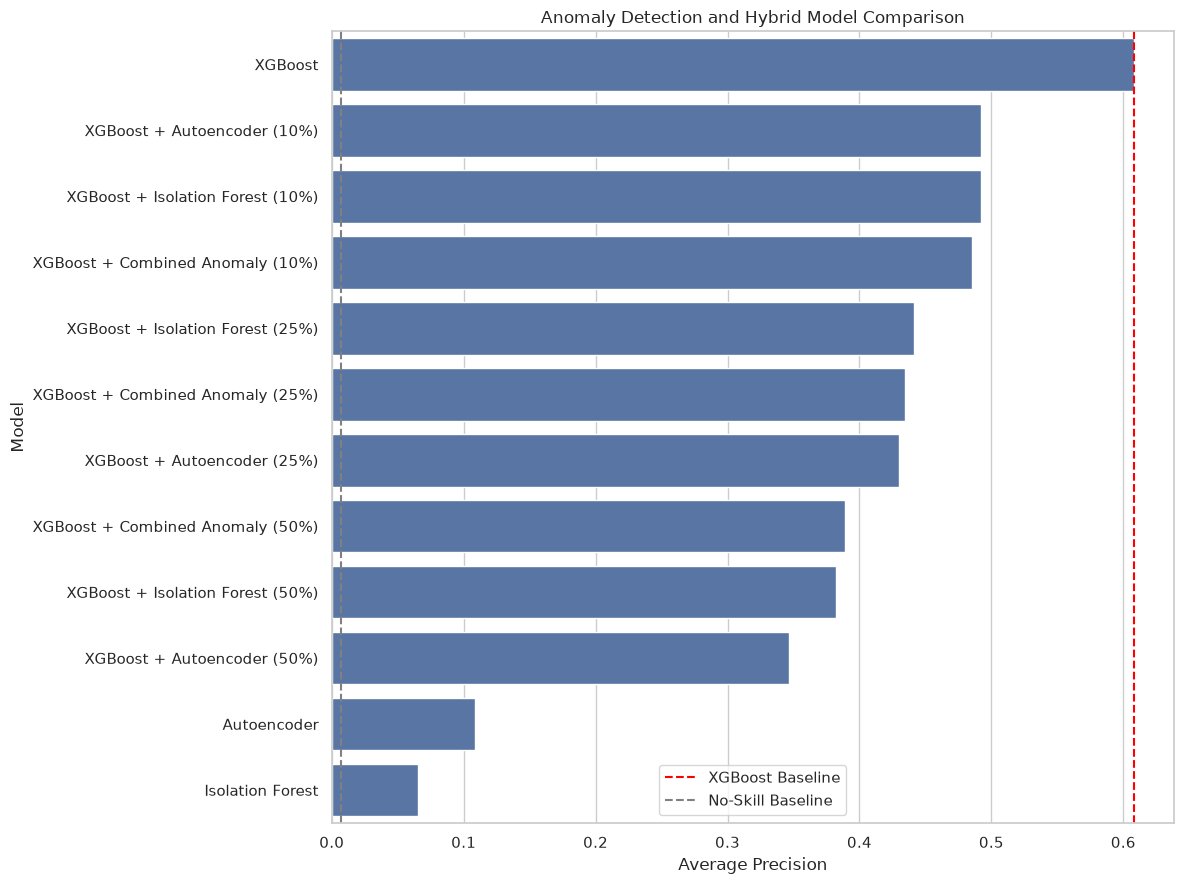

In [36]:
plt.figure(figsize=(12, 9))

sns.barplot(
    data=results_df,
    x="average_precision",
    y="model"
)

plt.axvline(
    xgb_ap,
    color="red",
    linestyle="--",
    label="XGBoost Baseline"
)

plt.axvline(
    y_val.mean(),
    color="gray",
    linestyle="--",
    label="No-Skill Baseline"
)

plt.title("Anomaly Detection and Hybrid Model Comparison")
plt.xlabel("Average Precision")
plt.ylabel("Model")
plt.legend()
save_plot("anomaly_hybrid_model_comparison.png")

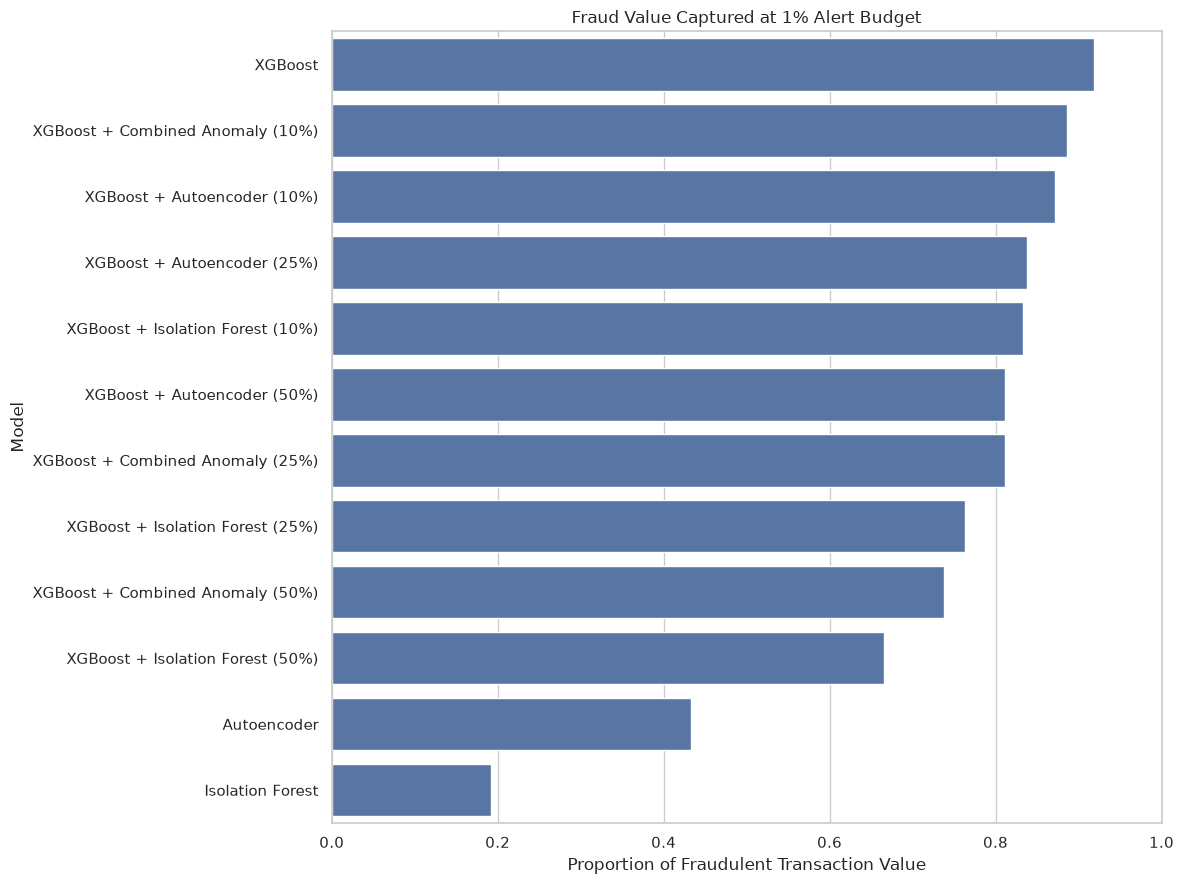

In [37]:
plt.figure(figsize=(12, 9))

sns.barplot(
    data=results_df.sort_values(
        "fraud_value_captured",
        ascending=False
    ),
    x="fraud_value_captured",
    y="model"
)

plt.title("Fraud Value Captured at 1% Alert Budget")
plt.xlabel("Proportion of Fraudulent Transaction Value")
plt.ylabel("Model")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

In [38]:
hybrid_results = results_df[
    results_df["model"].isin(
        hybrid_configs.keys()
    )
]

best_hybrid_row = hybrid_results.iloc[0]

best_hybrid_name = best_hybrid_row["model"]

best_hybrid_scores = predictions[
    best_hybrid_name
]

print("Best Hybrid Model:", best_hybrid_name)

best_hybrid_row

Best Hybrid Model: XGBoost + Autoencoder (10%)


model                          XGBoost + Autoencoder (10%)
average_precision                                  0.49246
roc_auc                                           0.967269
alert_rate                                            0.01
alert_count                                           2281
precision                                         0.398509
recall                                            0.585696
f1                                                0.474302
fraud_value_captured                                0.8717
true_positives                                         909
false_positives                                       1372
true_negatives                                      225179
false_negatives                                        643
ap_improvement                                   -0.115548
relative_ap_improvement_pct                     -19.004328
Name: 1, dtype: object

In [39]:
best_hybrid_ap = best_hybrid_row["average_precision"]

if best_hybrid_ap > xgb_ap:

    print("Hybrid model outperformed XGBoost.")

else:

    print("XGBoost remains the stronger model.")

print(f"XGBoost AP: {xgb_ap:.6f}")
print(f"Best Hybrid AP: {best_hybrid_ap:.6f}")

XGBoost remains the stronger model.
XGBoost AP: 0.608008
Best Hybrid AP: 0.492460


In [40]:
comparison_predictions = {
    "XGBoost": xgb_scores,
    "Isolation Forest": isolation_scores,
    "Autoencoder": autoencoder_scores,
    best_hybrid_name: best_hybrid_scores
}

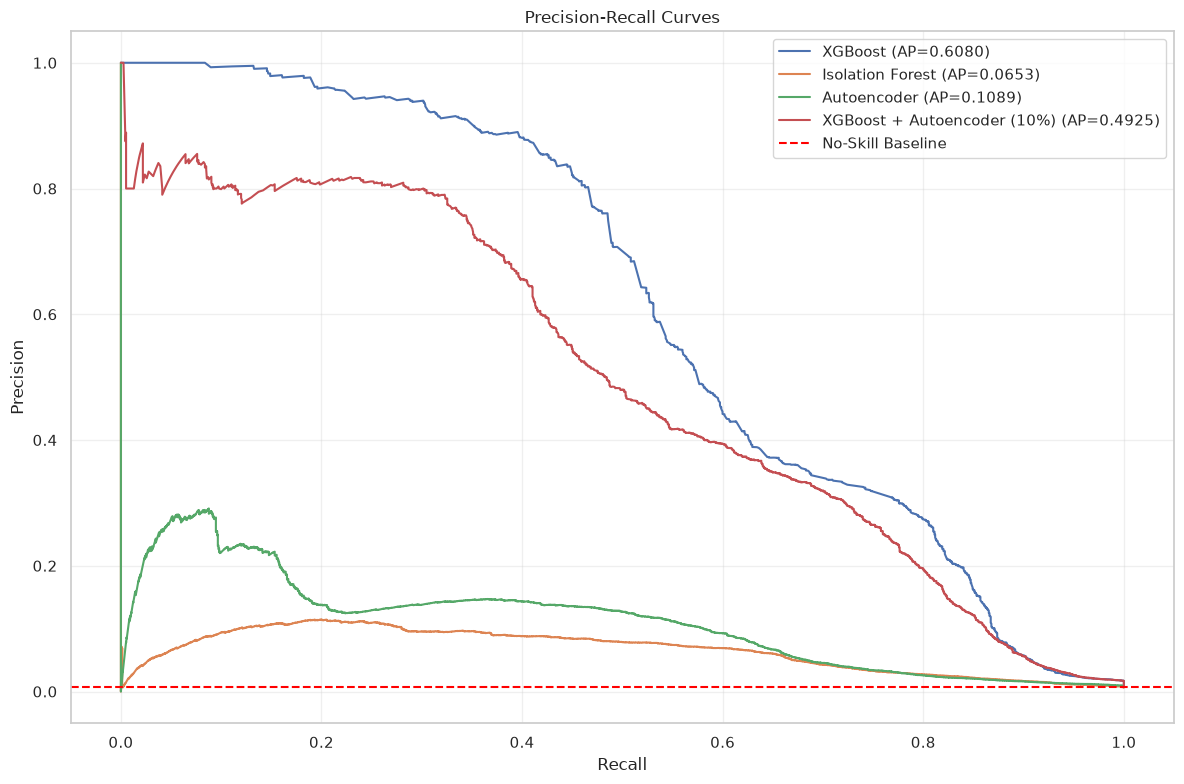

In [41]:
plt.figure(figsize=(12, 8))

for model_name, scores in comparison_predictions.items():

    precision, recall, _ = precision_recall_curve(
        y_val,
        scores
    )

    ap = average_precision_score(
        y_val,
        scores
    )

    plt.plot(
        recall,
        precision,
        label=f"{model_name} (AP={ap:.4f})"
    )

plt.axhline(
    y_val.mean(),
    color="red",
    linestyle="--",
    label="No-Skill Baseline"
)

plt.title("Precision-Recall Curves")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.grid(alpha=0.3)
save_plot("anomaly_precision_recall.png")

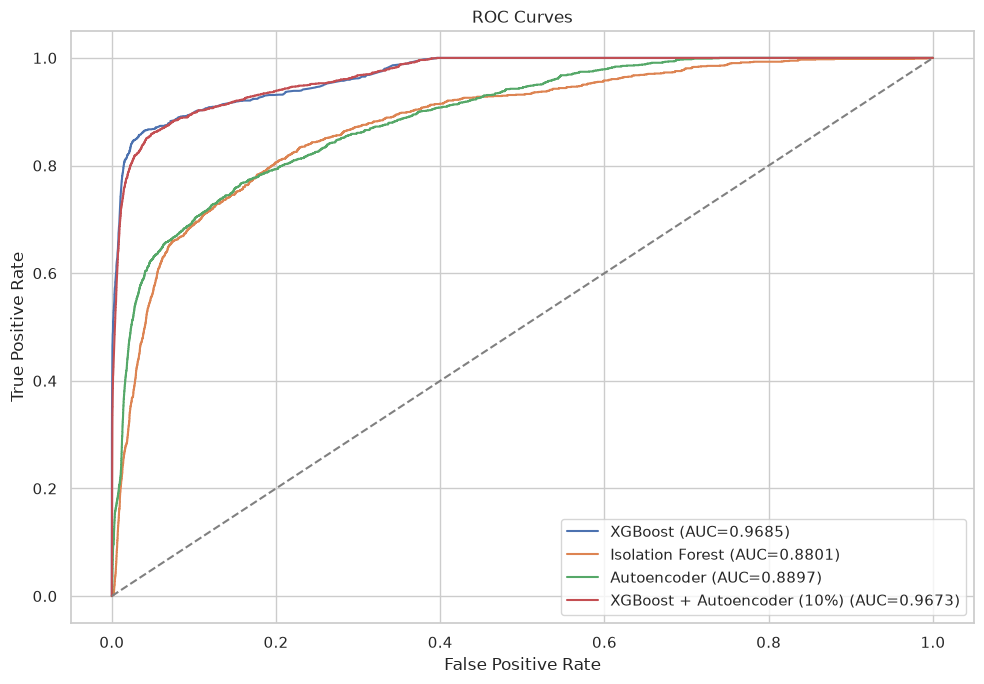

In [42]:
plt.figure(figsize=(10, 7))

for model_name, scores in comparison_predictions.items():

    fpr, tpr, _ = roc_curve(
        y_val,
        scores
    )

    auc = roc_auc_score(
        y_val,
        scores
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC={auc:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray"
)

plt.title("ROC Curves")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()

In [43]:
alert_rates = [
    0.001,
    0.005,
    0.01,
    0.02,
    0.05,
    0.10
]

budget_results = []

for model_name, scores in comparison_predictions.items():

    for alert_rate in alert_rates:

        metrics = evaluate_anomaly_model(
            model_name,
            y_val,
            scores,
            val_df["amount"],
            alert_rate=alert_rate
        )

        budget_results.append(metrics)

budget_results_df = pd.DataFrame(budget_results)

budget_results_df.head()

,model,average_precision,roc_auc,alert_rate,alert_count,precision,recall,f1,fraud_value_captured,true_positives,false_positives,true_negatives,false_negatives
0,XGBoost,0.608008,0.96851,0.001,228,0.991228,0.145619,0.253933,0.362929,226,2,226549,1326
1,XGBoost,0.608008,0.96851,0.005,1140,0.691228,0.507732,0.585438,0.842333,788,352,226199,764
2,XGBoost,0.608008,0.96851,0.010,2281,0.418238,0.614691,0.497782,0.918656,954,1327,225224,598
3,XGBoost,0.608008,0.96851,0.020,4562,0.272907,0.802191,0.407262,0.968742,1245,3317,223234,307
4,XGBoost,0.608008,0.96851,0.050,11405,0.118018,0.867268,0.207764,0.984073,1346,10059,216492,206


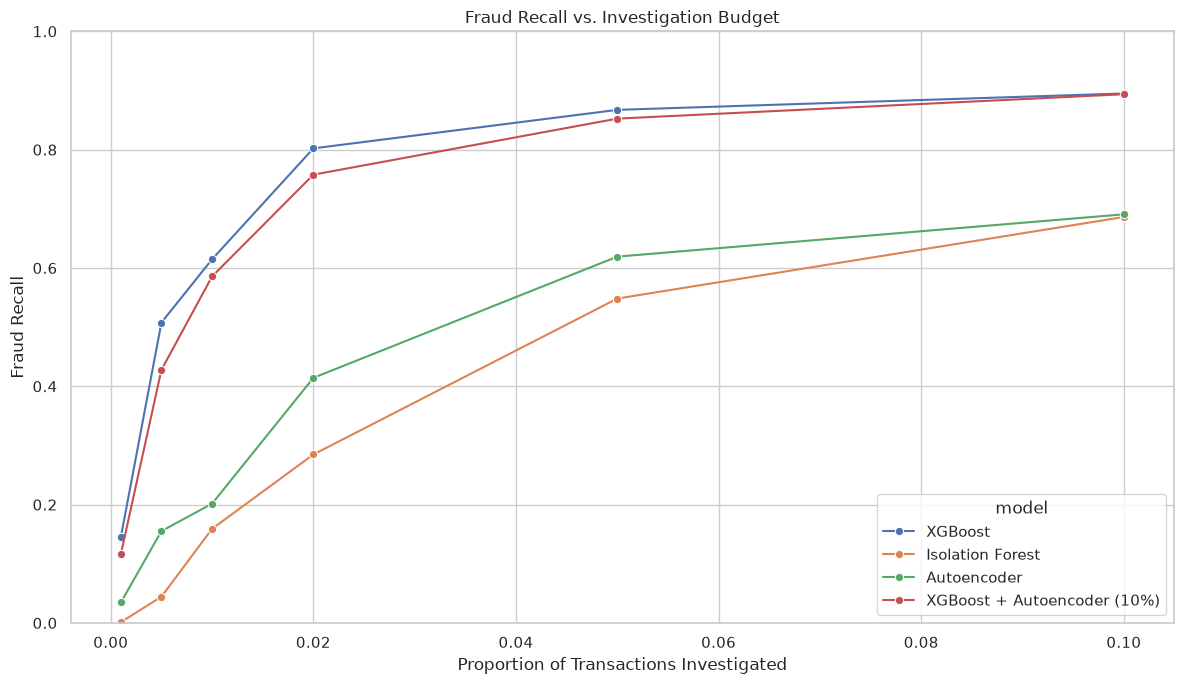

In [44]:
plt.figure(figsize=(12, 7))

sns.lineplot(
    data=budget_results_df,
    x="alert_rate",
    y="recall",
    hue="model",
    marker="o"
)

plt.title("Fraud Recall vs. Investigation Budget")
plt.xlabel("Proportion of Transactions Investigated")
plt.ylabel("Fraud Recall")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

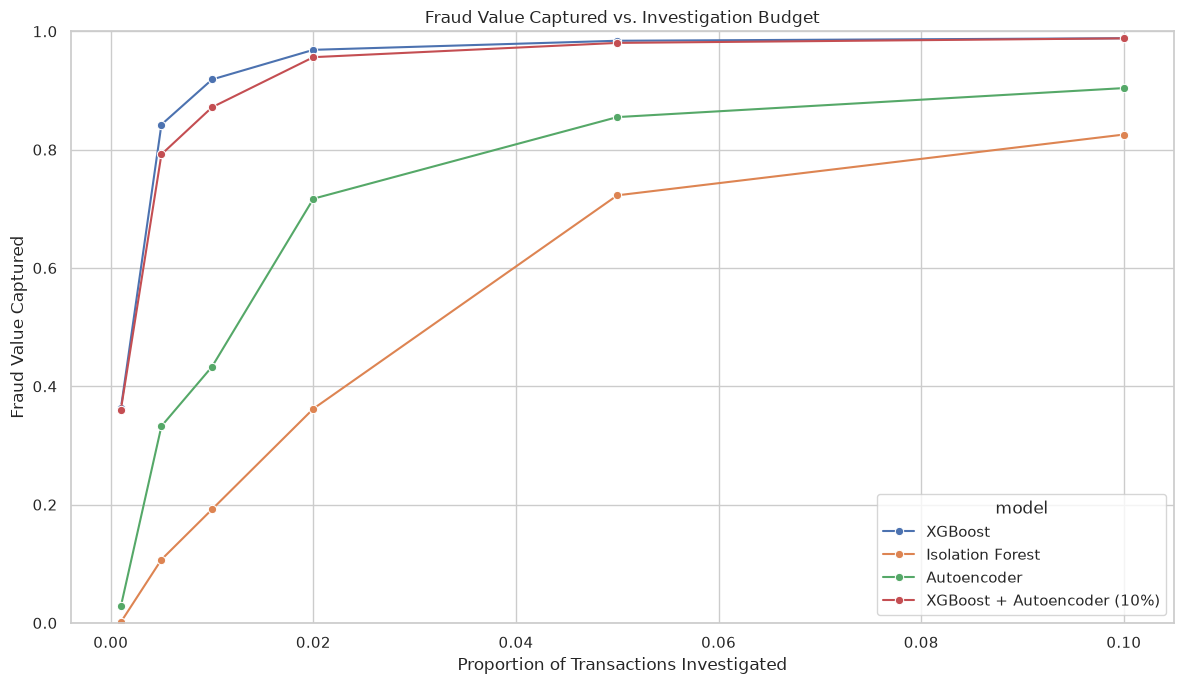

In [45]:
plt.figure(figsize=(12, 7))

sns.lineplot(
    data=budget_results_df,
    x="alert_rate",
    y="fraud_value_captured",
    hue="model",
    marker="o"
)

plt.title("Fraud Value Captured vs. Investigation Budget")
plt.xlabel("Proportion of Transactions Investigated")
plt.ylabel("Fraud Value Captured")
plt.ylim(0, 1)
save_plot("anomaly_fraud_value_vs_budget.png")

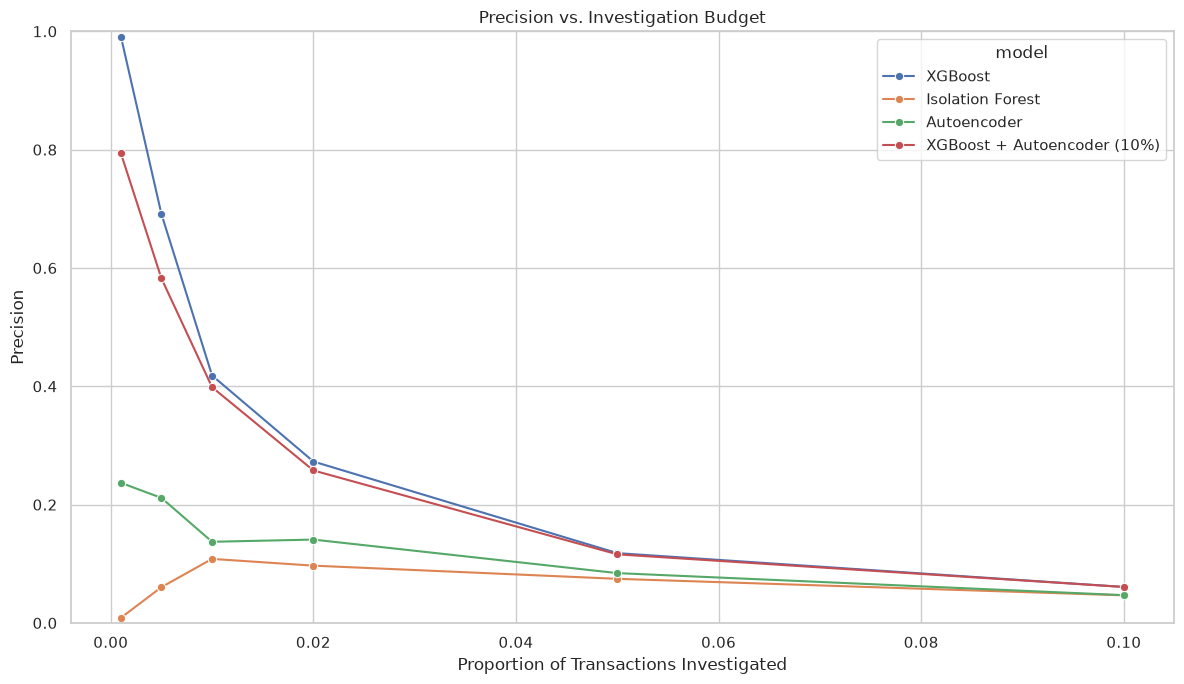

In [46]:
plt.figure(figsize=(12, 7))

sns.lineplot(
    data=budget_results_df,
    x="alert_rate",
    y="precision",
    hue="model",
    marker="o"
)

plt.title("Precision vs. Investigation Budget")
plt.xlabel("Proportion of Transactions Investigated")
plt.ylabel("Precision")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [47]:
fraud_analysis = val_df.loc[
    y_val == 1,
    [
        "type",
        "amount",
        "recipient_is_new",
        "recipient_prior_count"
    ]
].copy()

fraud_analysis["xgb_score"] = xgb_scores[
    y_val.to_numpy() == 1
]

fraud_analysis["isolation_score"] = isolation_scores[
    y_val.to_numpy() == 1
]

fraud_analysis["autoencoder_score"] = autoencoder_scores[
    y_val.to_numpy() == 1
]

In [48]:
for model_name, scores in comparison_predictions.items():

    flagged_indices = get_flagged_indices(scores)

    detected = np.zeros(len(val_df), dtype=bool)

    detected[list(flagged_indices)] = True

    fraud_analysis[f"{model_name}_detected"] = (
        detected[y_val.to_numpy() == 1]
    )

fraud_analysis.head()

,type,amount,recipient_is_new,recipient_prior_count,xgb_score,isolation_score,autoencoder_score,XGBoost_detected,Isolation Forest_detected,Autoencoder_detected,XGBoost + Autoencoder (10%)_detected
0,TRANSFER,7782452.17,1,0,0.044538,0.603499,0.068231,True,False,True,True
1,CASH_OUT,7782452.17,1,0,0.612814,0.538121,0.090264,True,False,True,True
2,TRANSFER,171878.27,1,0,0.015969,0.570175,0.046403,False,False,False,False
3,CASH_OUT,171878.27,0,20,0.000443,0.474133,0.000102,False,False,False,False
4,TRANSFER,311487.14,1,0,0.015969,0.571972,0.019472,False,False,False,False


In [49]:
detection_columns = [
    col for col in fraud_analysis.columns
    if col.endswith("_detected")
]

fraud_analysis.groupby(
    "type",
    observed=True
)[detection_columns].mean()

,XGBoost_detected,Isolation Forest_detected,Autoencoder_detected,XGBoost + Autoencoder (10%)_detected
type,,,,
CASH_OUT,0.538660,0.015464,0.077320,0.340206
TRANSFER,0.690722,0.302835,0.326031,0.831186


In [50]:
fraud_analysis.groupby(
    "recipient_is_new"
)[detection_columns].mean()

,XGBoost_detected,Isolation Forest_detected,Autoencoder_detected,XGBoost + Autoencoder (10%)_detected
recipient_is_new,,,,
0,0.504303,0.020654,0.053356,0.271945
1,0.680742,0.242019,0.290422,0.773429


In [51]:
missed_by_xgb = fraud_analysis.loc[
    ~fraud_analysis["XGBoost_detected"]
]

missed_by_xgb[
    [
        "amount",
        "recipient_prior_count",
        "isolation_score",
        "autoencoder_score"
    ]
].describe()

,amount,recipient_prior_count,isolation_score,autoencoder_score
count,5.980000e+02,598.000000,598.000000,598.000000
mean,2.765003e+05,3.474916,0.539984,0.020885
std,2.992109e+05,6.588799,0.046458,0.040559
min,0.000000e+00,0.000000,0.420275,0.000037
25%,6.813014e+04,0.000000,0.500834,0.000169
50%,1.642969e+05,0.000000,0.547711,0.000617
75%,3.997180e+05,4.000000,0.582008,0.015035
max,1.463764e+06,49.000000,0.617750,0.142377


In [52]:
missed_by_xgb[
    detection_columns
].sum()

XGBoost_detected                          0
Isolation Forest_detected                 0
Autoencoder_detected                    100
XGBoost + Autoencoder (10%)_detected    113
dtype: int64

In [53]:
efficiency_df = pd.DataFrame([
    {
        "model": "Isolation Forest",
        "training_rows": len(X_normal),
        "training_time_seconds": isolation_training_time
    },
    {
        "model": "Autoencoder",
        "training_rows": len(X_normal),
        "training_time_seconds": autoencoder_training_time
    }
])

efficiency_df

,model,training_rows,training_time_seconds
0,Isolation Forest,95893,0.473297
1,Autoencoder,95893,10.378701


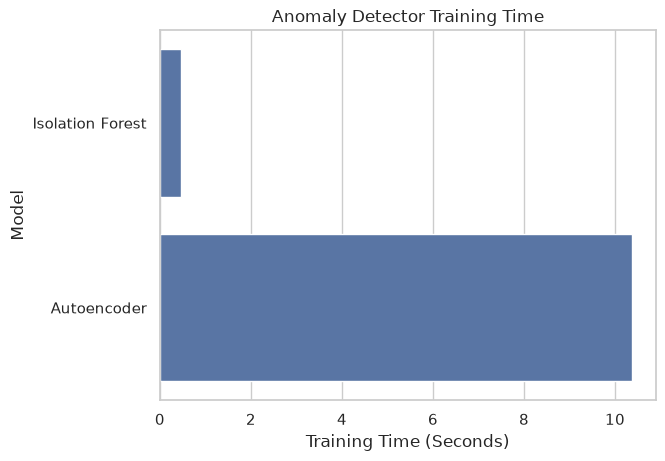

In [54]:
sns.barplot(
    data=efficiency_df,
    x="training_time_seconds",
    y="model"
)

plt.title("Anomaly Detector Training Time")
plt.xlabel("Training Time (Seconds)")
plt.ylabel("Model")
plt.show()

In [55]:
isolation_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("detector", isolation_model)
])

joblib.dump(
    isolation_pipeline,
    MODEL_PATH / "isolation_forest.joblib"
)

['../models/isolation_forest.joblib']

In [56]:
autoencoder_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("autoencoder", autoencoder)
])

joblib.dump(
    autoencoder_pipeline,
    MODEL_PATH / "autoencoder.joblib"
)

['../models/autoencoder.joblib']

In [57]:
reference_scores = {
    "xgboost": np.sort(xgb_reference_scores),
    "isolation_forest": np.sort(
        isolation_reference_scores
    ),
    "autoencoder": np.sort(
        autoencoder_reference_scores
    )
}

joblib.dump(
    reference_scores,
    MODEL_PATH / "anomaly_reference_scores.joblib"
)

['../models/anomaly_reference_scores.joblib']

In [58]:
anomaly_metadata = {
    "training_strategy": "normal_only",
    "normal_sample_rate": NORMAL_SAMPLE_RATE,
    "training_rows": len(X_normal),
    "reference_rows": len(X_reference),
    "feature_columns": anomaly_features,
    "supervised_feature_columns": feature_columns,
    "isolation_forest_params": isolation_params,
    "autoencoder_params": autoencoder_params,
    "score_normalization": "training_reference_percentile",
    "selection_metric": "average_precision",
    "best_hybrid_model": best_hybrid_name,
    "best_hybrid_config": hybrid_configs[best_hybrid_name],
    "best_hybrid_average_precision": float(best_hybrid_ap),
    "xgboost_average_precision": float(xgb_ap),
    "hybrid_outperformed_xgboost": bool(
        best_hybrid_ap > xgb_ap
    ),
    "random_state": RANDOM_STATE,
    "test_set_evaluated": False
}

with open(
    MODEL_PATH / "anomaly_model_metadata.json",
    "w"
) as f:

    json.dump(
        anomaly_metadata,
        f,
        indent=4
    )

In [59]:
results_df.to_csv(
    RESULTS_PATH / "anomaly_model_results.csv",
    index=False
)

overlap_results.to_csv(
    RESULTS_PATH / "anomaly_overlap_results.csv",
    index=False
)

budget_results_df.to_csv(
    RESULTS_PATH / "anomaly_alert_budget_results.csv",
    index=False
)

efficiency_df.to_csv(
    RESULTS_PATH / "anomaly_training_efficiency.csv",
    index=False
)

## Key Findings

### Normal-Only Training Strategy
- Implemented semi-supervised anomaly detection by training models exclusively on legitimate transactions.
- Used memory-efficient PyArrow batch reading to process 100,000 transactions at a time.
- Randomly sampled approximately 2% of legitimate training transactions.
- Retained 119,867 legitimate transactions:
  - 95,893 model training transactions
  - 23,974 reference transactions
- Excluded fraudulent transactions from anomaly detector training.
- Retained the complete chronological validation dataset of 228,103 transactions, including 1,552 fraudulent transactions.
- Excluded the original transaction amount from anomaly detection features to reduce redundancy with log-transformed amount.
- Applied logarithmic transformations, median imputation, standardization, and one-hot encoding.
- Transformed 11 original predictive features into 15 processed features.
- Fitted all preprocessing transformations exclusively on normal training transactions.
- All preprocessing validation checks passed successfully.
- The held-out test dataset was not accessed.

### Isolation Forest Performance
- Trained Isolation Forest using 150 isolation trees and a maximum of 1,024 sampled observations per tree.
- Fraudulent transactions received higher average anomaly scores than legitimate transactions:
  - Legitimate mean anomaly score: 0.492201
  - Fraudulent mean anomaly score: 0.577705
- Achieved the following validation performance:
  - Average Precision: 0.065316
  - ROC-AUC: 0.880083
- At a 1% investigation budget:
  - Precision: 10.8286%
  - Recall: 15.9149%
  - F1-score: 0.128881
  - Fraudulent transaction value captured: 19.2137%
  - True positives: 247
  - False positives: 2,034
- Isolation Forest outperformed the no-skill baseline but performed substantially worse than supervised XGBoost.
- Unusual transaction behavior alone was insufficient to reliably distinguish fraudulent from legitimate transactions.

### Autoencoder Performance
- Implemented a fully connected autoencoder using Scikit-learn's MLPRegressor.
- Used the following neural network architecture:
  - Input layer: 15 features
  - Encoder: 32 neurons
  - Bottleneck: 8 neurons
  - Decoder: 32 neurons
  - Output layer: 15 reconstructed features
- Trained the network using the Adam optimizer and squared reconstruction error.
- Completed 60 training epochs with a final training loss of approximately 0.000544.
- The optimizer reached its maximum iteration limit before convergence.
- Achieved the following validation performance:
  - Average Precision: 0.108950
  - ROC-AUC: 0.889739
- At a 1% investigation budget:
  - Precision: 13.7221%
  - Recall: 20.1675%
  - F1-score: 0.163319
  - Fraudulent transaction value captured: 43.3310%
  - True positives: 313
  - False positives: 1,968
- The autoencoder outperformed Isolation Forest across all evaluated predictive metrics.

### Reconstruction Error Patterns

| Statistic | Legitimate | Fraudulent |
|---|---:|---:|
| Mean Reconstruction Error | 0.001266 | 0.026736 |
| Median Reconstruction Error | 0.000116 | 0.007109 |
| Standard Deviation | 0.008477 | 0.040190 |

- Fraudulent transactions exhibited approximately 21 times higher mean reconstruction error than legitimate transactions.
- The median fraudulent reconstruction error was approximately 61 times higher than the legitimate median.
- These results suggest that the autoencoder learned representations of normal transaction behavior.
- However, reconstruction error distributions overlap substantially.
- Some legitimate transactions received higher reconstruction errors than fraudulent transactions.
- Reconstruction error is therefore an indicator of abnormal behavior rather than a definitive indicator of fraud.

### Comparison Against Supervised Models

All models were evaluated under an identical 1% investigation budget of 2,281 validation transactions.

| Model | Average Precision | ROC-AUC | Precision | Recall | Fraud Value Captured |
|---|---:|---:|---:|---:|---:|
| XGBoost | 0.608008 | 0.968510 | 41.82% | 61.47% | 91.87% |
| Autoencoder | 0.108950 | 0.889739 | 13.72% | 20.17% | 43.33% |
| Isolation Forest | 0.065316 | 0.880083 | 10.83% | 15.91% | 19.21% |

- Both anomaly detectors outperformed the no-skill Average Precision baseline of approximately 0.006804.
- Supervised XGBoost substantially outperformed both standalone anomaly detection models.
- XGBoost benefited from learning directly from labeled fraudulent and legitimate transactions.
- Anomaly detection alone was insufficient to replace supervised classification within the PaySim dataset.

### Complementary Fraud Detection and Model Overlap

| Model | Fraud Detected | Also Detected by XGBoost | Missed by XGBoost |
|---|---:|---:|---:|
| Isolation Forest | 247 | 247 | 0 |
| Autoencoder | 313 | 213 | 100 |

- Isolation Forest did not identify additional fraudulent transactions beyond those already detected by XGBoost.
- The autoencoder identified 100 fraudulent transactions that XGBoost missed under the same investigation budget.
- Approximately 31.95% of the autoencoder's true-positive detections were not detected by XGBoost.
- These findings demonstrate complementary detection capabilities for reconstruction-based anomaly detection.
- However, complementary detections do not necessarily translate into improved ensemble performance because additional detections may displace other correctly identified fraudulent transactions.

### Impact of Percentile Normalization
- Converted model scores into empirical percentiles using legitimate training-period reference transactions.
- This normalization enabled comparison and combination of scores originating from different model architectures.
- Reference-based normalization avoids requiring access to an entire future transaction batch when scoring individual transactions.
- Evaluated the effect of percentile normalization independently of hybrid score combination.

| Metric | Original XGBoost | Percentile-Normalized XGBoost |
|---|---:|---:|
| Average Precision | 0.608008 | 0.592769 |
| ROC-AUC | 0.968510 | 0.968498 |
| Precision | 0.418238 | 0.417799 |
| Recall | 0.614691 | 0.614046 |
| F1-score | 0.497782 | 0.497261 |
| Fraud Value Captured | 0.918656 | 0.918646 |
| True Positives | 954 | 953 |
| False Positives | 1,327 | 1,328 |

- Percentile normalization reduced Average Precision by approximately 2.51%.
- ROC-AUC remained nearly unchanged.
- At the 1% investigation budget, normalization resulted in only one fewer fraudulent transaction being detected.
- Fraudulent transaction value captured remained approximately 91.87%.
- Empirical percentile transformations may introduce score saturation and tied values, reducing ranking resolution among high-risk transactions.
- Normalization contributed to performance degradation but did not explain the entire reduction observed in the hybrid models.

### Hybrid Model Performance
- Investigated hybrid fraud risk scores by combining percentile-normalized XGBoost predictions with anomaly detection scores.
- Evaluated three anomaly score sources:
  - Isolation Forest
  - Autoencoder
  - Combined Isolation Forest and autoencoder scores
- Tested anomaly score weights of 10%, 25%, and 50%, producing nine hybrid configurations.

| Hybrid Configuration | Average Precision | ROC-AUC |
|---|---:|---:|
| XGBoost + Autoencoder (10%) | 0.492460 | 0.967269 |
| XGBoost + Isolation Forest (10%) | 0.492212 | 0.966835 |
| XGBoost + Combined Anomaly (10%) | 0.485347 | 0.967313 |
| XGBoost + Isolation Forest (25%) | 0.441392 | 0.962846 |
| XGBoost + Combined Anomaly (25%) | 0.434243 | 0.964548 |
| XGBoost + Autoencoder (25%) | 0.429796 | 0.964035 |
| XGBoost + Combined Anomaly (50%) | 0.389370 | 0.954605 |
| XGBoost + Isolation Forest (50%) | 0.382273 | 0.950119 |
| XGBoost + Autoencoder (50%) | 0.346822 | 0.950474 |

- The strongest hybrid configuration combined XGBoost with a 10% autoencoder score contribution.
- The strongest hybrid achieved:
  - Average Precision: 0.492460
  - ROC-AUC: 0.967269
  - Precision: 39.8509%
  - Recall: 58.5696%
  - F1-score: 0.474302
  - Fraudulent transaction value captured: 87.1700%
  - True positives: 909
  - False positives: 1,372
- None of the nine hybrid configurations outperformed standalone XGBoost.
- The strongest hybrid reduced Average Precision by 19.00% relative to standalone XGBoost.
- The strongest hybrid also performed worse than percentile-normalized XGBoost, indicating that normalization alone was not responsible for the performance reduction.
- Standalone XGBoost remains the preferred model for subsequent evaluation.

### Impact of Hybrid Score Weighting
- Increasing anomaly score contributions consistently reduced Average Precision within each tested hybrid model family.
- Hybrid configurations with a 10% anomaly contribution outperformed their corresponding 25% and 50% configurations.
- These findings suggest that the supervised XGBoost scores contain stronger fraud-ranking information than the anomaly detection scores under the evaluated configurations.
- Simple weighted averaging did not effectively leverage the complementary detection capabilities of the autoencoder.
- More sophisticated ensemble strategies may be investigated as future extensions.
- Increasing model complexity does not necessarily improve predictive performance.

### Investigation Budget Analysis
- Evaluated model performance across investigation budgets ranging from 0.1% to 10% of validation transactions.
- Compared models using equal investigation capacity rather than arbitrary numerical score thresholds.

Selected XGBoost investigation budget results:

| Alert Budget | Alerts | Precision | Recall | Fraud Value Captured |
|---|---:|---:|---:|---:|
| 0.1% | 228 | 99.12% | 14.56% | 36.29% |
| 0.5% | 1,140 | 69.12% | 50.77% | 84.23% |
| 1.0% | 2,281 | 41.82% | 61.47% | 91.87% |
| 2.0% | 4,562 | 27.29% | 80.22% | 96.87% |
| 5.0% | 11,405 | 11.80% | 86.73% | 98.41% |

- Increasing investigation capacity improves fraud recall and fraudulent transaction value captured.
- Precision decreases as additional lower-risk transactions are flagged.
- Increasing the investigation budget from 0.5% to 1.0% improves fraudulent transaction value captured by approximately 7.63 percentage points.
- Increasing the investigation budget from 2.0% to 5.0% requires 6,843 additional investigations while improving fraudulent transaction value captured by only approximately 1.53 percentage points.
- These findings demonstrate diminishing returns as investigation capacity increases.
- Selecting an appropriate investigation budget requires balancing financial detection performance against operational investigation costs.
- Retrospective top-k evaluation does not directly represent a live transaction decision policy because the entire evaluation batch is available for ranking.

### Fraudulent Transaction Value Captured

| Model | Fraud Value Captured at 1% Budget |
|---|---:|
| XGBoost | 91.87% |
| XGBoost + Combined Anomaly (10%) | 88.62% |
| XGBoost + Autoencoder (10%) | 87.17% |
| XGBoost + Isolation Forest (10%) | 83.33% |
| Autoencoder | 43.33% |
| Isolation Forest | 19.21% |

- Standalone XGBoost achieved the strongest financial detection performance among all evaluated anomaly and hybrid models.
- The autoencoder captured more than twice as much fraudulent transaction value as Isolation Forest.
- The hybrid model with the highest Average Precision was not the hybrid with the highest fraudulent transaction value captured.
- Financial transaction value provides an important complement to conventional classification metrics.
- Detected fraudulent transaction value should not be interpreted directly as realized financial losses prevented.

### Missed Fraud Analysis
- Standalone XGBoost missed 598 fraudulent transactions at the 1% investigation budget.
- Missed fraudulent transactions had:
  - Mean transaction amount: approximately 276,500
  - Median transaction amount: approximately 164,297
  - Mean recipient prior transaction count: approximately 3.47
- The autoencoder detected 100 fraudulent transactions missed by XGBoost.
- The strongest hybrid detected 113 fraudulent transactions missed by standalone XGBoost.
- However, the hybrid displaced 158 fraudulent transactions correctly detected by standalone XGBoost, resulting in a net reduction of 45 true-positive detections.

#### Fraud Recall by Transaction Type

| Transaction Type | XGBoost | Isolation Forest | Autoencoder | Best Hybrid |
|---|---:|---:|---:|---:|
| CASH_OUT | 53.87% | 1.55% | 7.73% | 34.02% |
| TRANSFER | 69.07% | 30.28% | 32.60% | 83.12% |

- Both anomaly detectors performed substantially better on fraudulent TRANSFER transactions than CASH_OUT transactions.
- The strongest hybrid improved TRANSFER fraud recall by approximately 14.05 percentage points relative to standalone XGBoost.
- However, CASH_OUT fraud recall decreased by approximately 19.85 percentage points.
- This suggests that anomaly detection may be more useful for specific transaction categories rather than as a universal addition to supervised classification.

#### Fraud Recall by Recipient History

| Recipient Status | XGBoost | Isolation Forest | Autoencoder | Best Hybrid |
|---|---:|---:|---:|---:|
| Existing Recipient | 50.43% | 2.07% | 5.34% | 27.19% |
| New Recipient | 68.07% | 24.20% | 29.04% | 77.34% |

- All evaluated models achieved higher recall for fraudulent transactions involving new recipients.
- The strongest hybrid improved recall for new recipients but substantially reduced recall for existing recipients.
- Historical recipient behavior remains relevant to understanding model strengths and weaknesses.
- Subgroup-specific evaluation reveals performance differences that aggregate metrics alone may conceal.

### Computational Efficiency

| Model | Training Rows | Training Time |
|---|---:|---:|
| Isolation Forest | 95,893 | 0.61 seconds |
| Autoencoder | 95,893 | 12.84 seconds |

- Both anomaly detectors were trained using the same legitimate transaction sample.
- Isolation Forest trained approximately 21 times faster than the autoencoder in this experiment.
- The autoencoder achieved stronger anomaly detection performance at the expense of additional computational cost.
- Batch prediction and float32 feature representations were used to reduce memory consumption.
- Memory-efficient data loading allowed the experiments to be conducted without loading the entire training dataset into memory.
- Training time measurements represent individual experimental runs rather than general performance guarantees.

### Model Limitations
- Normal-only training assumes that historical legitimate transaction labels are reliable.
- Random sampling may exclude uncommon legitimate transaction patterns that are important for learning normal behavior.
- Anomalous behavior is not necessarily fraudulent behavior.
- The autoencoder reached its maximum iteration limit before convergence.
- Only a limited number of standalone anomaly detector configurations were evaluated.
- Reconstruction errors may be influenced by feature scaling, redundancy, and missing-value imputation.
- Percentile normalization may reduce ranking resolution through score saturation and tied values.
- Simple weighted score averaging may not adequately capture complementary relationships between models.
- Hybrid weights were selected using the validation dataset, potentially introducing optimistic model selection estimates.
- Anomaly scores and hybrid scores are not calibrated fraud probabilities.
- Fraud detection performance varies across transaction types and recipient history groups.
- PaySim is a synthetic dataset, limiting conclusions about real-world generalization and previously unseen fraud patterns.
- Final generalization performance remains unknown because the held-out test dataset has not been evaluated.

### Model Artifacts and Reproducibility
- Saved the fitted Isolation Forest preprocessing and detection pipeline using Joblib.
- Saved the fitted autoencoder preprocessing and reconstruction pipeline.
- Preserved the training reference score distributions required for reproducible percentile normalization.
- Saved anomaly detection metadata, model hyperparameters, and the strongest hybrid configuration.
- Exported the following experimental results:
  - Anomaly model comparison results
  - Fraud detection overlap results
  - Investigation budget results
  - Computational efficiency results
- Configured six standalone figure exports covering anomaly score distributions, autoencoder training loss, hybrid model comparison, precision-recall curves, and fraud value versus investigation budget.
- Maintained consistent random seeds, feature definitions, chronological data partitions, and evaluation metrics.

### Implications for Final Model Selection
- Retain standalone XGBoost as the leading fraud detection model based on validation Average Precision and financial detection performance.
- Preserve LightGBM as a competitive supervised alternative from the advanced modeling phase.
- Preserve Isolation Forest and the autoencoder as experimental anomaly detection models.
- Do not incorporate hybrid models into the final system without demonstrated predictive or operational improvements.
- Consider subgroup-specific anomaly detection or more sophisticated ensemble strategies as future extensions.
- Prioritize probability calibration before interpreting supervised model scores as fraud probabilities.
- Perform cost-sensitive classification threshold optimization.
- Evaluate the trade-off between fraudulent transaction value captured and false-positive investigation costs.
- Investigate operational risk tiers and investigation capacity constraints.
- Finalize model selection and decision policies before evaluating the held-out test dataset.

## Conclusion

The anomaly detection phase investigated Isolation Forest, neural network-based reconstruction anomaly detection, and nine hybrid fraud detection configurations.

The autoencoder demonstrated stronger standalone anomaly detection performance than Isolation Forest and identified 100 fraudulent transactions that were missed by XGBoost under an identical investigation budget.

However, none of the evaluated hybrid configurations improved upon standalone XGBoost. The strongest hybrid achieved a validation Average Precision of 0.492460 compared to 0.608008 for standalone XGBoost.

The percentile normalization experiment demonstrated that score transformation contributed to performance degradation but was not sufficient to explain the decline observed in hybrid models.

Standalone XGBoost also achieved the strongest financial detection performance, capturing approximately 91.87% of fraudulent transaction value while investigating only 1% of validation transactions.

Subgroup analysis revealed that anomaly detection was more effective for fraudulent TRANSFER transactions and transactions involving new recipients, suggesting potential opportunities for targeted anomaly detection strategies.

These findings demonstrate that increasing model complexity does not necessarily improve predictive performance and that alternative modeling approaches should be evaluated empirically before being incorporated into a production system.

Standalone XGBoost will remain the leading candidate for final model evaluation.

The next phase will focus on probability calibration, cost-sensitive threshold optimization, operational fraud decision policies, and held-out test evaluation.